# Can acoustic search find recordings that neural LSH missed?
Two independent retrieval paths search the same FMA Large catalogue. The neural path proposes five recording groups. The acoustic path searches the entire catalogue and proposes up to five groups. On known development clips we compared a pitch-invariant triplet index with a speed-probed peak-pair index that votes for a common time offset. The third variant checks the alignment of the best 64 peak-pair candidates before proposing five. We selected by recoveries outside the original five, then by acoustic-only coverage. A wider neural shortlist controls for the extra candidate slots. All three systems verify candidates with the same alignment algorithm.

This notebook reproduces the held-out recognition counts from candidate-level scores and the latency summary from individual GPU measurements. It runs on a CPU with NumPy, pandas and Matplotlib. The [experiment notes](../reports/acoustic-search.md) describe the full GPU run.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/acoustic_evaluation.py').exists())
sys.path.insert(0, str(root / 'scripts'))
from acoustic_evaluation import METHODS, counts, decisions
reports = root / 'reports'
with np.load(reports / 'acoustic-nominations.npz') as f:
    data = {k: f[k] for k in f}
result = json.loads((reports / 'acoustic-results.json').read_text())
selection = json.loads((reports / 'acoustic-selection.json').read_text())
print('Development nomination comparison:', selection)
timing = pd.read_csv(reports / 'acoustic-latency.csv')
held = data['phase'] == 'test'
assert (held & data['known']).sum() == (held & ~data['known']).sum() == 512
names = {'lsh5':'LSH 5', 'lsh10':'LSH 10', 'dual':'LSH + acoustic'}

Development nomination comparison: {'development_known': 512, 'development_misses': 16, 'methods': {'triplet': {'misses_recovered': 0, 'acoustic_top5': 17}, 'offset_pairs': {'misses_recovered': 4, 'acoustic_top5': 370}, 'offset_pairs_aligned': {'misses_recovered': 5, 'acoustic_top5': 399}}, 'selected': 'offset_pairs_aligned'}


## Where did each query go?
The raw pool is the union before reranking. Top five and top one below use the fusion weight chosen for closed-set identification on development songs. The 1% development target allows at most five of 512 absent clips to receive a title. The last three outcome columns use that separately calibrated rule on the 512 known and 512 absent held-out clips.

In [2]:
rows = []
for m in METHODS:
    runs = result['methods'][m]
    for tag, run in runs.items():
        assert counts(data, m, run['rule'], held) == run['test']
    closed = runs['closed']['test']
    open_set = runs['0.01']['test']
    rows.append([names[m], closed['pool'], closed['top5'], closed['top1'],
                 open_set['correct'], open_set['wrong_known'], open_set['fa'],
                 timing[m].median(), timing[m].quantile(.95)])
table = pd.DataFrame(rows, columns=['Method','Raw pool','Final five','Top one','Correct accepted',
                                    'Wrong known','False absent','Median ms','p95 ms']).set_index('Method')
table.round(2)

,Raw pool,Final five,Top one,Correct accepted,Wrong known,False absent,Median ms,p95 ms
Method,,,,,,,,
LSH 5,490,490,488,418,1,9,15.74,16.66
LSH 10,491,491,489,418,1,9,15.90,16.74
LSH + acoustic,503,503,500,427,1,10,18.35,19.48


## Follow the original 22 misses
Rank zero means the correct group never entered the candidate pool. The recovery counts distinguish a nomination from a correct first-place identification and an accepted answer. These are previously examined clips and provide a paired diagnostic.

In [3]:
misses = pd.read_csv(reports / 'acoustic-original-misses.csv')
miss_indices = np.flatnonzero(held & data['known'] & ~(data['lsh10_groups'][:, :5] == data['group_id'][:,None]).any(1))
np.testing.assert_array_equal(misses['query'], miss_indices)
print(f'{len(misses)} clips from {misses.group_id.nunique()} recording groups')
for m in ('lsh10', 'dual'):
    g, _, _ = decisions(data, m, result['methods'][m]['closed']['rule'])
    match = g[miss_indices] == data['group_id'][miss_indices,None]
    rank = np.where(match.any(1), match.argmax(1)+1, 0)
    np.testing.assert_array_equal(rank, misses[m+'_rank'])
    print(names[m], 'in pool / final five / first / correct accepted:',
          (rank>0).sum(), ((rank>0)&(rank<=5)).sum(), (rank==1).sum(), misses[m+'_correct_accepted'].sum())
misses.groupby('distortion')[['lsh10_rank','dual_rank']].agg(lambda ranks: f'{(ranks>0).sum()}/{len(ranks)}')

22 clips from 21 recording groups
LSH 10 in pool / final five / first / correct accepted: 1 1 1 0
LSH + acoustic in pool / final five / first / correct accepted: 13 13 13 9


,lsh10_rank,dual_rank
distortion,,
noise,0/1,1/1
speed_up,0/6,6/6
speed_up+voice_over+compression,1/12,4/12
voice_over,0/3,2/3


## Recognition and latency on the same GPU
Each of 64 decoded held-out clips went through each warm method in random order. The parallel method submits acoustic nomination and neural encoding on separate CUDA streams. The timer includes query feature extraction, retrieval, alignment and the final decision. Reference construction, capture and file decoding are outside the timer.

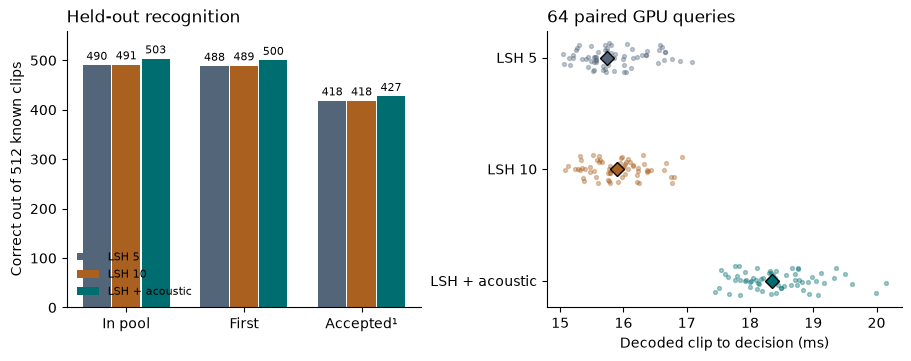

¹ At the 1% development target. Held-out false accepts: {'LSH 5': 9, 'LSH 10': 9, 'LSH + acoustic': 10}


In [4]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(9, 3.5), layout='constrained')
colors = ['#526579', '#aa601f', '#006d70']
x = np.arange(3)
for j, (_, row) in enumerate(table.iterrows()):
    bars = ax.bar(x + (j-1)*.25, row[['Raw pool','Top one','Correct accepted']].astype(int),
                  width=.24, color=colors[j], label=table.index[j])
    ax.bar_label(bars, fmt='%.0f', padding=2, fontsize=8)
ax.set(xticks=x, xticklabels=['In pool','First','Accepted¹'], ylabel='Correct out of 512 known clips', ylim=(0,560))
ax.legend(frameon=False, fontsize=8, loc='lower left')
for j, m in enumerate(METHODS):
    bx.scatter(timing[m], np.full(len(timing),j)+np.random.default_rng(52).uniform(-.13,.13,len(timing)),
               s=8, color=colors[j], alpha=.35)
    bx.plot(timing[m].median(),j,'D',ms=7,color=colors[j],markeredgecolor='black')
bx.set(yticks=range(3), yticklabels=list(names.values()), xlabel='Decoded clip to decision (ms)')
bx.invert_yaxis()
ax.set_title('Held-out recognition', loc='left')
bx.set_title('64 paired GPU queries', loc='left')
for axis in (ax,bx):
    axis.spines[['top','right']].set_visible(False)
fig.savefig(reports / 'acoustic-search.pdf', bbox_inches='tight')
plt.show()
print('¹ At the 1% development target. Held-out false accepts:', table['False absent'].to_dict())

## What changes with the operating point?
Each cell shows correct accepted known clips and false accepts on absent clips. Both denominators are 512. Thresholds and weights for every point were selected on development songs before this evaluation.

In [5]:
pd.DataFrame({names[m]: {tag: f"{r['test']['correct']} correct / {r['test']['fa']} false"
                         for tag, r in result['methods'][m].items() if tag != 'closed'} for m in METHODS})

,LSH 5,LSH 10,LSH + acoustic
0.0025,222 correct / 3 false,222 correct / 3 false,226 correct / 3 false
0.01,418 correct / 9 false,418 correct / 9 false,427 correct / 10 false
0.02,473 correct / 12 false,479 correct / 15 false,488 correct / 11 false
0.05,482 correct / 26 false,484 correct / 30 false,494 correct / 27 false
0.1,481 correct / 47 false,486 correct / 46 false,497 correct / 49 false
